# EDA · Matriculacions de vehicles electrificats i híbrids a Catalunya (2017-2025)

In [ ]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.backends.backend_pdf import PdfPages
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

matplotlib.rcParams['figure.dpi'] = 150
plt.style.use('seaborn-v0_8-whitegrid')

DATA_DIR = Path('../data/processed')
DATA_DIR.mkdir(parents=True, exist_ok=True)

# PDF report handle (open once, close at end)
PDF_PATH = 'EDA_report.pdf'
pdf_pages = PdfPages(PDF_PATH)

def save_fig(fig, png_name):
    """Save figure as PNG and append to PDF."""
    fig.savefig(png_name, dpi=150, bbox_inches='tight')
    pdf_pages.savefig(fig, bbox_inches='tight')

# Thousands formatter
thousands_fmt = mticker.FuncFormatter(lambda x, _: f'{x:,.0f}')

# Colorblind-friendly palette
TECH_COLORS = plt.cm.tab10.colors

print('Llibreries carregades correctament.')

## 1. Càrrega i agregació de dades

In [3]:
import os

# Locate CSV (handles both accented and unaccented filename variants)
PROJECT_DIR = os.path.dirname(os.path.abspath('eda_matriculacions.ipynb'))
candidates = [f for f in os.listdir(PROJECT_DIR) if f.startswith('Matriculacions') and f.endswith('.csv')]
assert candidates, 'No s\'ha trobat el fitxer CSV al directori del projecte'
CSV_PATH = os.path.join(PROJECT_DIR, candidates[0])
print(f'Fitxer: {candidates[0]}')

raw = pd.read_csv(CSV_PATH, low_memory=False, encoding='utf-8')
print(f'Shape brut: {raw.shape}')
print(raw.head(3))

Fitxer: Matriculacions_mensuals_de_vehicles_electrificats_i_híbrids_a_Catalunya_20260525.csv


Shape brut: (284363, 15)
   Provincia      Comarca CPostal              Municipi  Codi IDESCAT  \
0  Barcelona  ALT PENEDES      ND  Sant Sadurní d'Anoia         82401   
1  Barcelona  ALT PENEDES      ND  Sant Sadurní d'Anoia         82401   
2  Barcelona  ALT PENEDES      ND              Subirats         82732   

    Tipus Vehicle Marca Model         Tecnologia Client Tipus alta  Mes   Any  \
0  01-Aut.Turisme    ND    ND  Gasolina/Elèctric     ND         ND    1  2017   
1  02-Tot Terreny    ND    ND  Gasolina/Elèctric     ND         ND    1  2017   
2  02-Tot Terreny    ND    ND  Gasolina/Elèctric     ND         ND    1  2017   

  Descripció  Uts  
0    Turisme    1  
1    Turisme    2  
2    Turisme    1  


In [4]:
# --- Aggregation per technology ---
agg_tech = (
    raw.groupby(['Any', 'Mes', 'Tecnologia'], as_index=False)['Uts']
       .sum()
       .rename(columns={'Uts': 'Matriculacions'})
)

# --- Aggregation total (all technologies) ---
agg_total = (
    raw.groupby(['Any', 'Mes'], as_index=False)['Uts']
       .sum()
       .rename(columns={'Uts': 'Matriculacions'})
)
agg_total['Tecnologia'] = 'Total'

# --- Combine ---
df = pd.concat([agg_tech, agg_total], ignore_index=True)

# --- Date column ---
df['date'] = pd.to_datetime(dict(year=df['Any'], month=df['Mes'], day=1))

# --- Sort ---
df = df.sort_values(['date', 'Tecnologia']).reset_index(drop=True)

# --- Column order ---
df = df[['Any', 'Mes', 'date', 'Tecnologia', 'Matriculacions']]

print(f'Shape combinat: {df.shape}')
print(f'Tecnologies: {sorted(df["Tecnologia"].unique())}')

Shape combinat: (742, 5)
Tecnologies: ['Diesel Mild Hybrid', 'Diesel/Elèctric', 'Diesel/Elèctric Endollable', 'Elèctric', 'Gas Mild Hybrid', 'Gasolina Mild Hybrid', 'Gasolina/Elèctric', 'Gasolina/Elèctric Endollable', 'Total']


In [5]:
# --- Check for missing month-technology combinations ---
all_dates = pd.date_range(
    df['date'].min(), df['date'].max(), freq='MS'
)
all_techs = df['Tecnologia'].unique().tolist()

full_idx = pd.MultiIndex.from_product(
    [all_dates, all_techs], names=['date', 'Tecnologia']
)
df_indexed = df.set_index(['date', 'Tecnologia'])
missing = full_idx.difference(df_indexed.index)

if len(missing) > 0:
    print(f'⚠ Combinacions absents: {len(missing)} → s\'ompliran amb 0')
    miss_df = pd.DataFrame(index=missing).reset_index()
    miss_df['Any'] = miss_df['date'].dt.year
    miss_df['Mes'] = miss_df['date'].dt.month
    miss_df['Matriculacions'] = 0
    miss_df = miss_df[['Any', 'Mes', 'date', 'Tecnologia', 'Matriculacions']]
    df = pd.concat([df, miss_df], ignore_index=True).sort_values(['date', 'Tecnologia']).reset_index(drop=True)
else:
    print('✓ Cap combinació absent.')

print(f'Shape final: {df.shape}')
print(f'Rang temporal: {df["date"].min().date()} → {df["date"].max().date()}')

⚠ Combinacions absents: 230 → s'ompliran amb 0
Shape final: (972, 5)
Rang temporal: 2017-01-01 → 2025-12-01


In [ ]:
# --- Save working dataset ---
df.to_csv(DATA_DIR / 'dataset_treball.csv', index=False, encoding='utf-8')
print(f'dataset_treball.csv desat a {DATA_DIR}: shape: {df.shape}')

# --- Summary ---
print('\n=== Matriculacions totals per tecnologia (desc) ===')
tot_per_tech = (
    df.groupby('Tecnologia')['Matriculacions']
      .sum()
      .sort_values(ascending=False)
)
print(tot_per_tech.apply(lambda x: f'{x:,.0f}').to_string())

print('\n=== Primeres 5 files ===')
print(df.head())
print('\n=== Últimes 5 files ===')
print(df.tail())

> **Nota sobre 2025:** Les dades arriben fins al desembre de 2025 (any complet). No cal truncar la sèrie.

## 2. Anàlisi Exploratòria de Dades (EDA)

### 2.1 Sèrie temporal: matriculacions mensuals totals

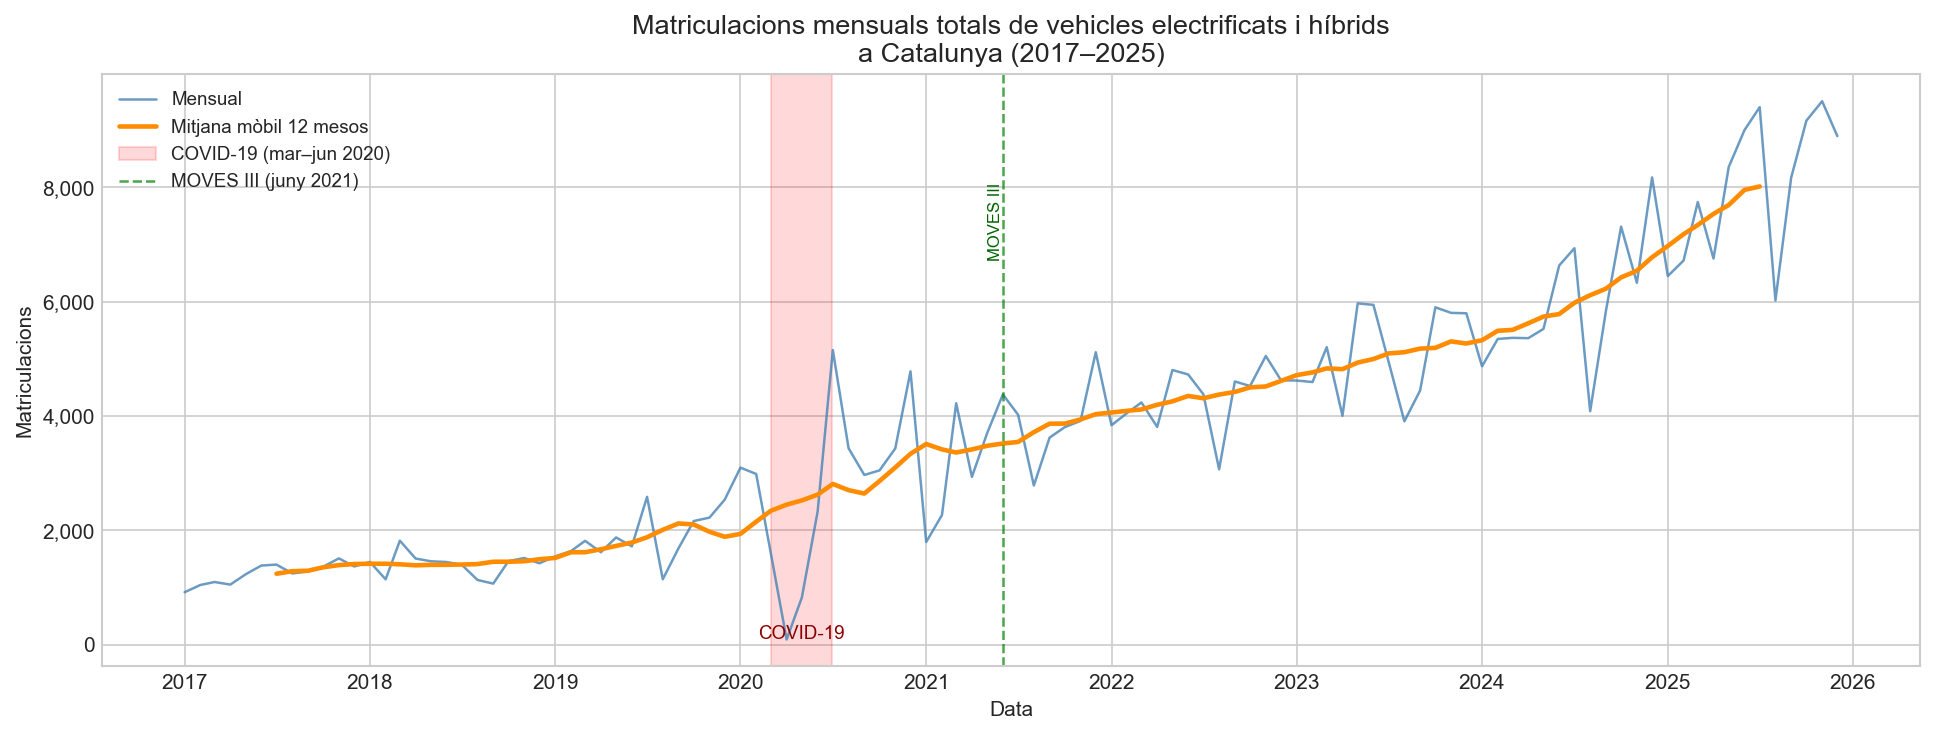

In [7]:
total = df[df['Tecnologia'] == 'Total'].set_index('date').sort_index()

rolling12 = total['Matriculacions'].rolling(12, center=True).mean()

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(total.index, total['Matriculacions'], color='steelblue',
        linewidth=1.2, alpha=0.8, label='Mensual')
ax.plot(rolling12.index, rolling12.values, color='darkorange',
        linewidth=2.2, label='Mitjana mòbil 12 mesos')

# COVID annotation
ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2020-06-30'),
           alpha=0.15, color='red', label='COVID-19 (mar–jun 2020)')
ax.annotate('COVID-19', xy=(pd.Timestamp('2020-05-01'), total['Matriculacions'].min() * 1.05),
            fontsize=9, color='darkred', ha='center')

# MOVES III annotation (incentiu vehicles electrics)
ax.axvline(pd.Timestamp('2021-06-01'), color='green', linestyle='--',
           linewidth=1.2, alpha=0.7, label='MOVES III (juny 2021)')
ax.annotate('MOVES III', xy=(pd.Timestamp('2021-06-01'), total['Matriculacions'].max() * 0.85),
            fontsize=8, color='darkgreen', rotation=90, va='top', ha='right')

ax.set_title('Matriculacions mensuals totals de vehicles electrificats i híbrids\na Catalunya (2017–2025)', fontsize=13)
ax.set_xlabel('Data')
ax.set_ylabel('Matriculacions')
ax.yaxis.set_major_formatter(thousands_fmt)
ax.legend(loc='upper left', fontsize=9)
fig.tight_layout()

save_fig(fig, 'fig_01_total_series.png')
plt.show()

### 2.2 Sèrie temporal per tecnologia (àrea apilada)

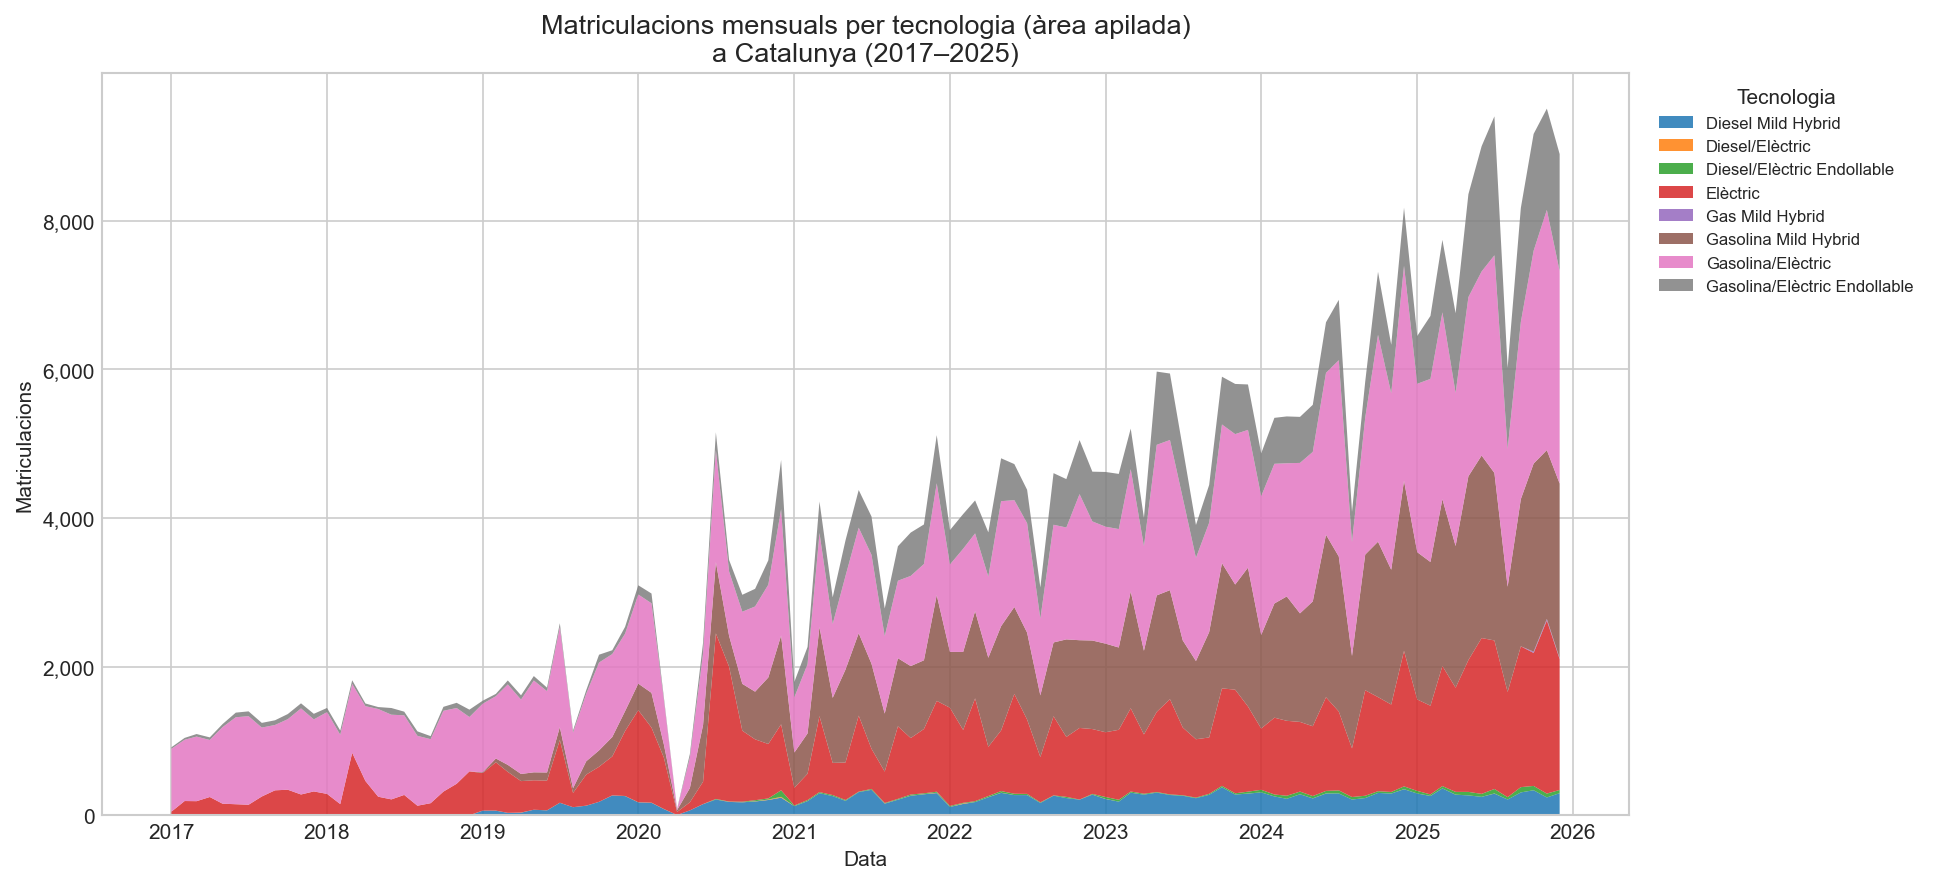

In [8]:
techs = [t for t in df['Tecnologia'].unique() if t != 'Total']
pivot = (
    df[df['Tecnologia'].isin(techs)]
    .pivot_table(index='date', columns='Tecnologia', values='Matriculacions', aggfunc='sum', fill_value=0)
)
pivot = pivot.sort_index()

fig, ax = plt.subplots(figsize=(13, 6))

ax.stackplot(pivot.index, [pivot[t] for t in pivot.columns],
             labels=pivot.columns.tolist(),
             colors=TECH_COLORS[:len(pivot.columns)], alpha=0.85)

ax.set_title('Matriculacions mensuals per tecnologia (àrea apilada)\na Catalunya (2017–2025)', fontsize=13)
ax.set_xlabel('Data')
ax.set_ylabel('Matriculacions')
ax.yaxis.set_major_formatter(thousands_fmt)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8, title='Tecnologia')
fig.tight_layout()

save_fig(fig, 'fig_02_stacked_area.png')
plt.show()

### 2.3 Evolució de la quota de mercat per tecnologia (àrea 100%)

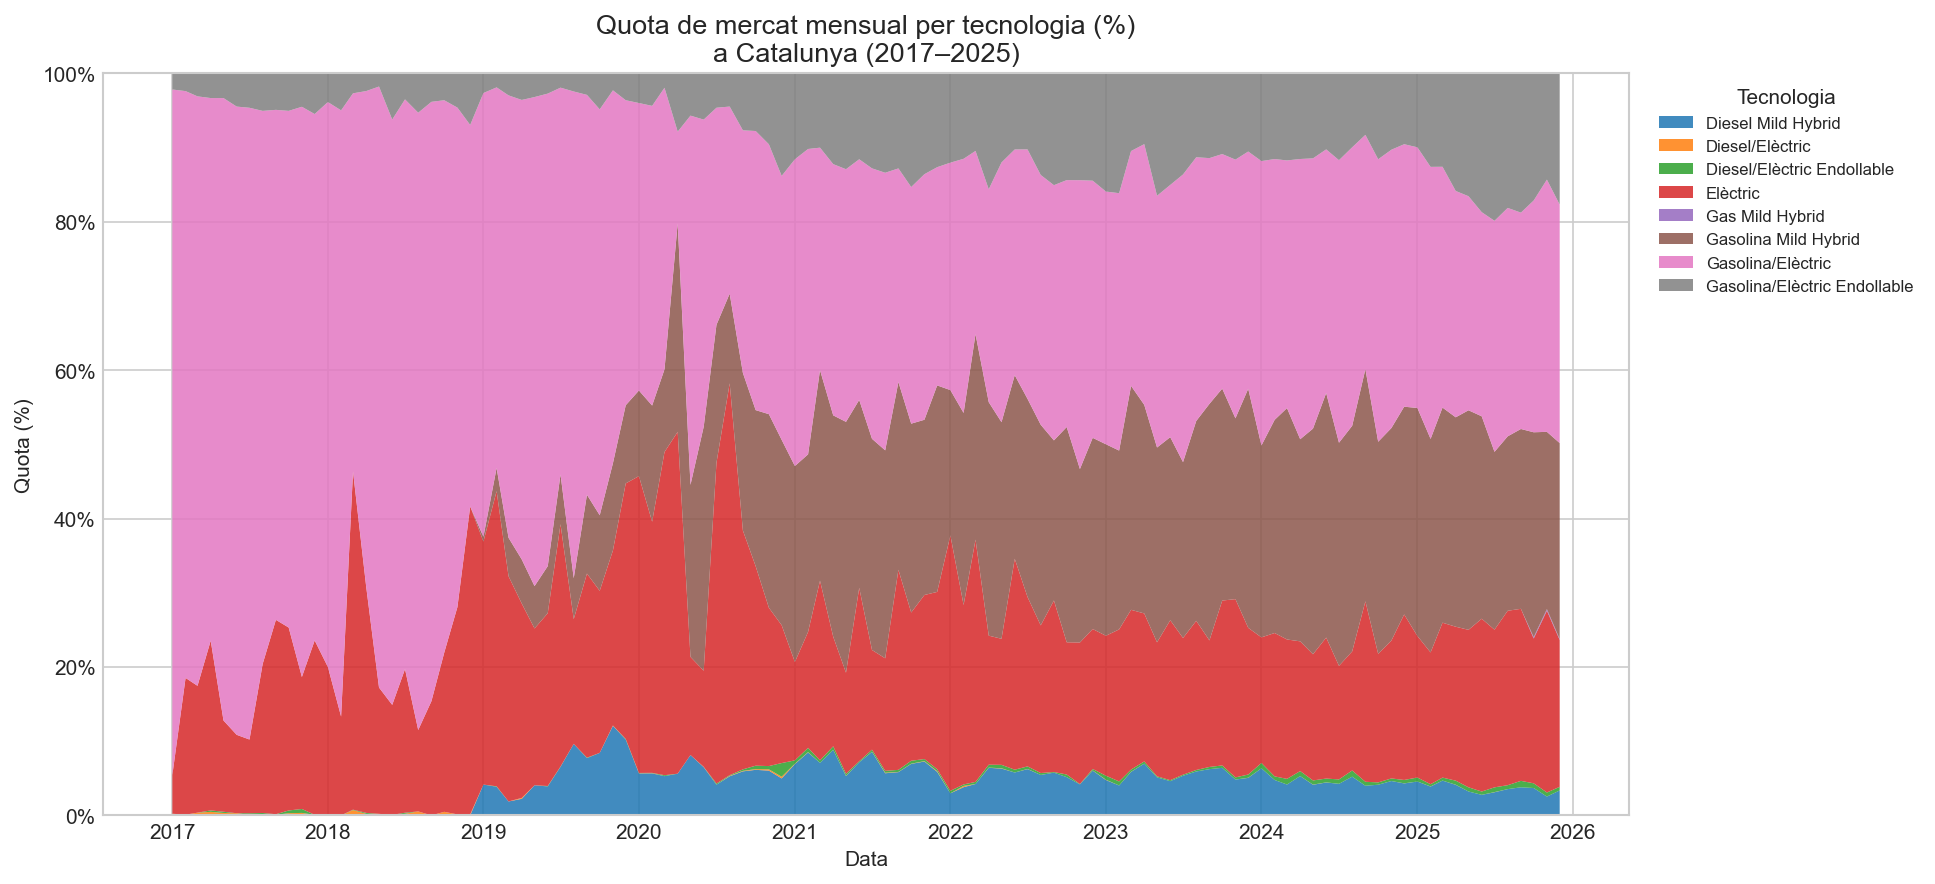

In [9]:
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(13, 6))

ax.stackplot(pivot_pct.index, [pivot_pct[t] for t in pivot_pct.columns],
             labels=pivot_pct.columns.tolist(),
             colors=TECH_COLORS[:len(pivot_pct.columns)], alpha=0.85)

ax.set_title('Quota de mercat mensual per tecnologia (%)\na Catalunya (2017–2025)', fontsize=13)
ax.set_xlabel('Data')
ax.set_ylabel('Quota (%)')
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8, title='Tecnologia')
fig.tight_layout()

save_fig(fig, 'fig_03_market_share.png')
plt.show()

### 2.4 Descomposició estacional (sèrie total)

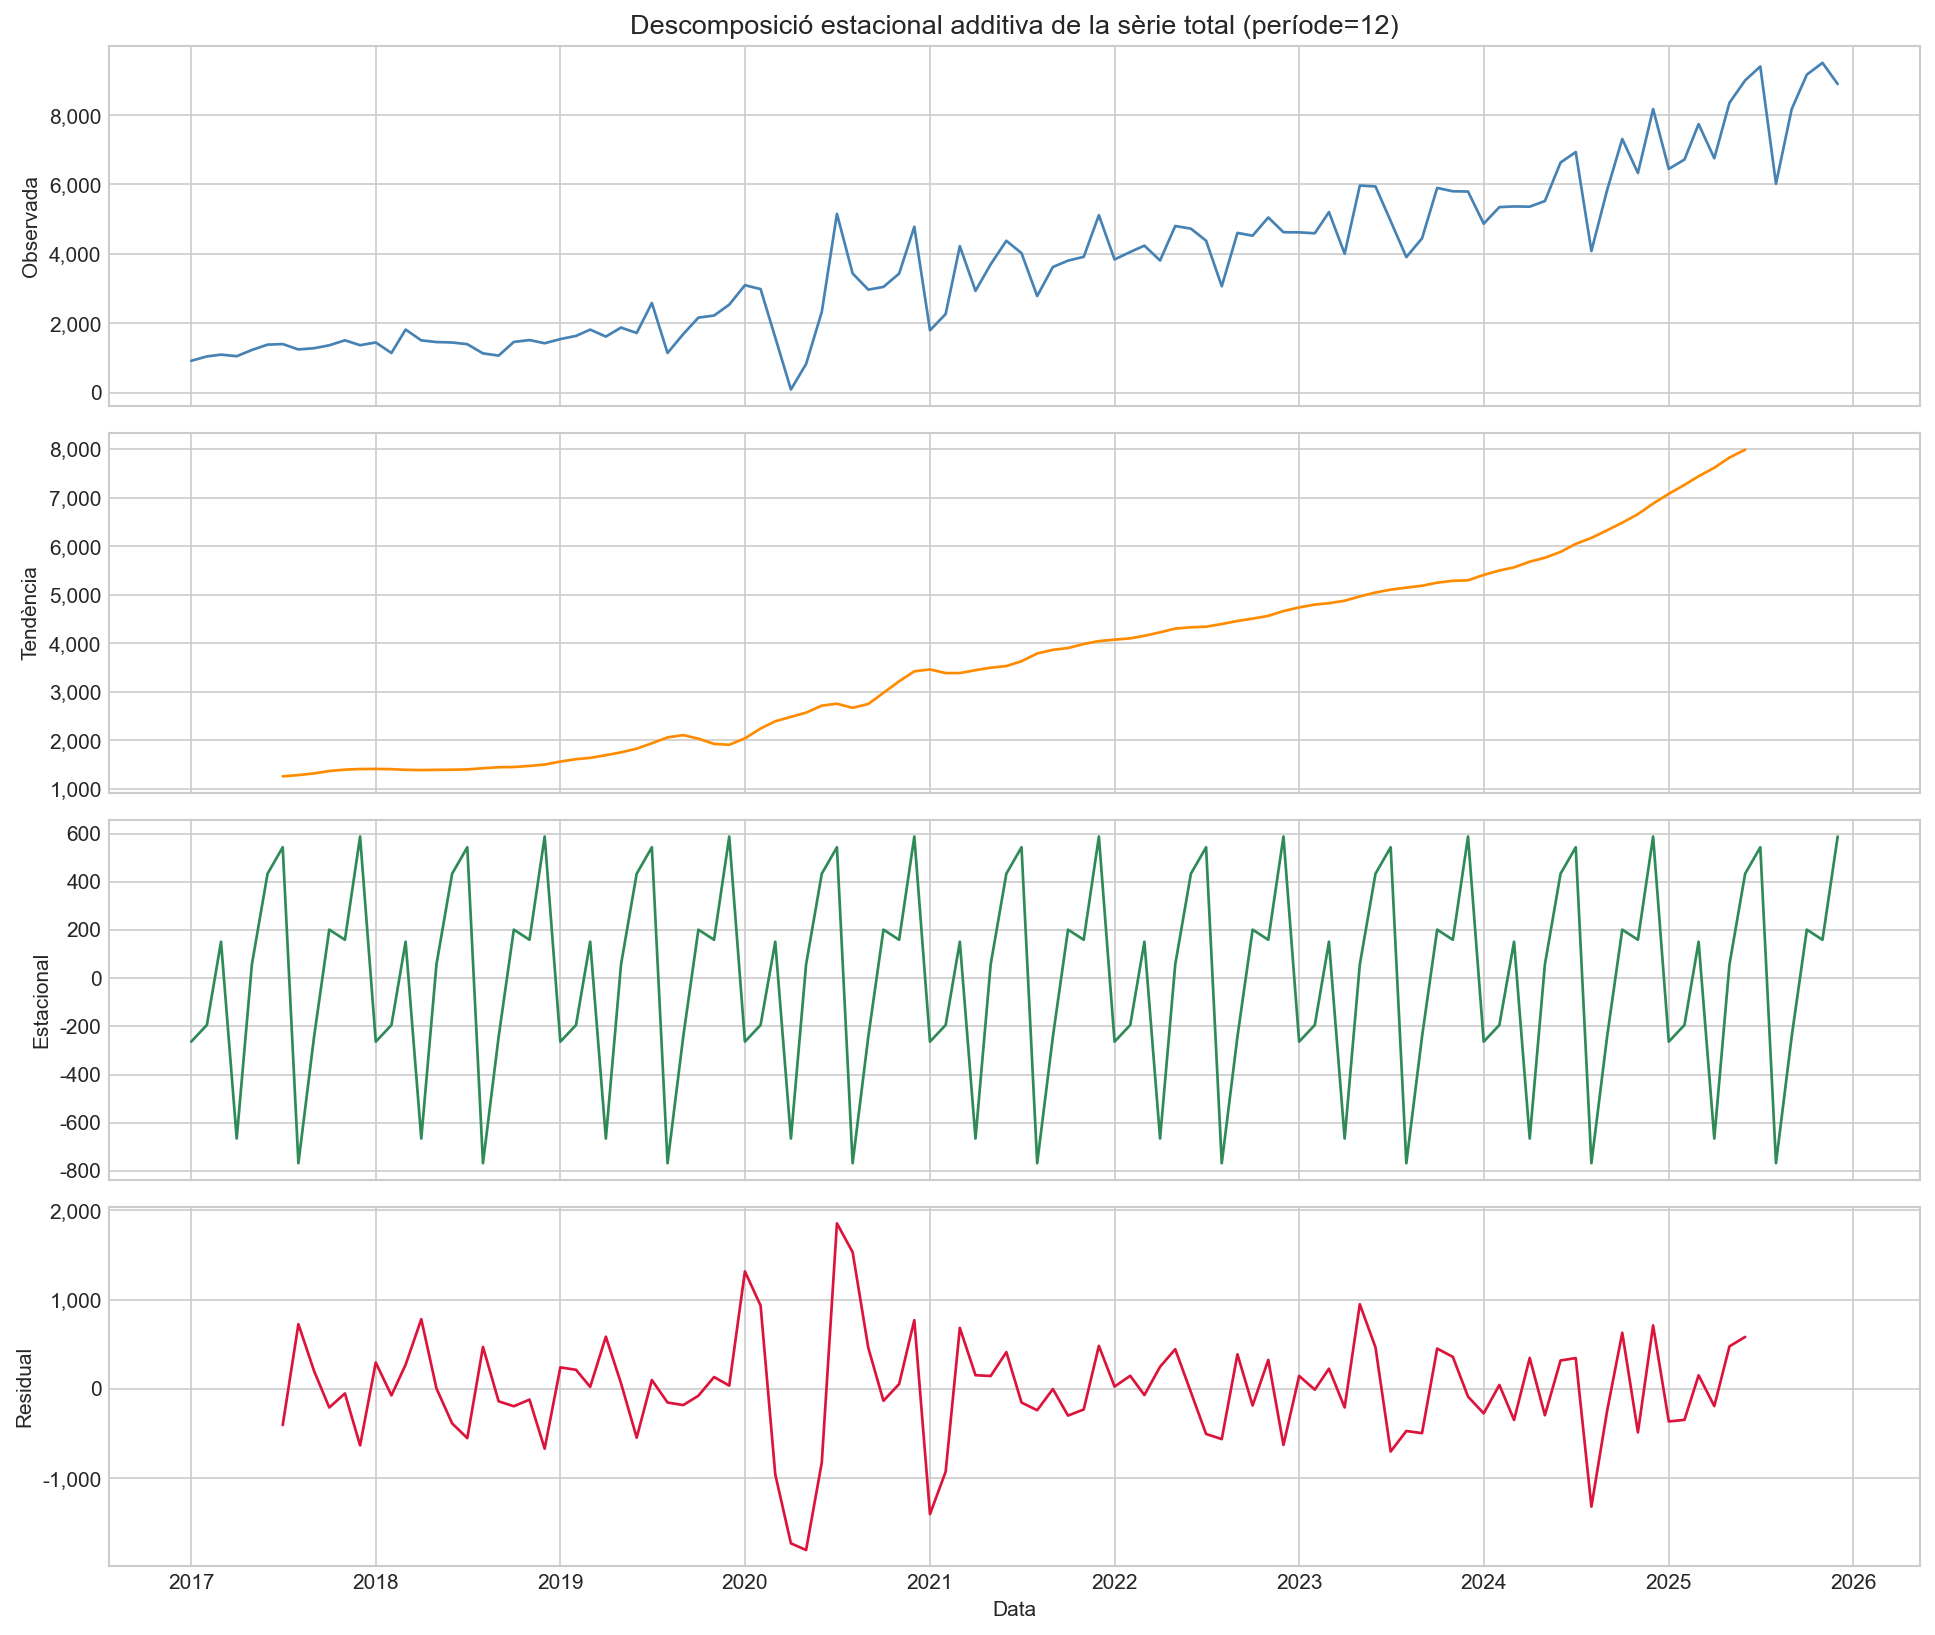

In [10]:
ts_total = total['Matriculacions'].asfreq('MS')

decomp = seasonal_decompose(ts_total, model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)
components = [
    (decomp.observed,  'Observada',  'steelblue'),
    (decomp.trend,     'Tendència',  'darkorange'),
    (decomp.seasonal,  'Estacional', 'seagreen'),
    (decomp.resid,     'Residual',   'crimson'),
]
for ax, (series, label, color) in zip(axes, components):
    ax.plot(series.index, series.values, color=color, linewidth=1.3)
    ax.set_ylabel(label, fontsize=10)
    ax.yaxis.set_major_formatter(thousands_fmt)

axes[0].set_title('Descomposició estacional additiva de la sèrie total (període=12)', fontsize=13)
axes[-1].set_xlabel('Data')
fig.tight_layout()

save_fig(fig, 'fig_04_decomposition.png')
plt.show()

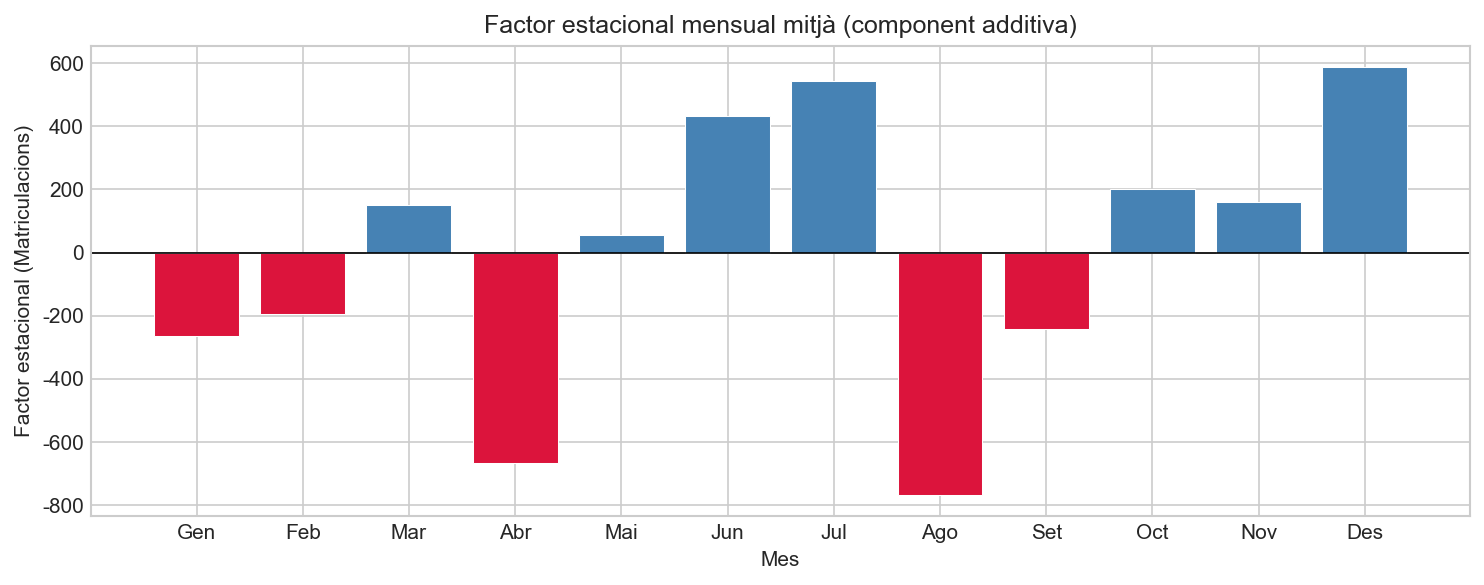

In [11]:
# Average seasonal factor by month
seasonal_by_month = decomp.seasonal.groupby(decomp.seasonal.index.month).mean()
month_labels = ['Gen', 'Feb', 'Mar', 'Abr', 'Mai', 'Jun',
                'Jul', 'Ago', 'Set', 'Oct', 'Nov', 'Des']

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(range(1, 13), seasonal_by_month.values,
              color=['steelblue' if v >= 0 else 'crimson' for v in seasonal_by_month.values],
              edgecolor='white', linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.set_title('Factor estacional mensual mitjà (component additiva)', fontsize=12)
ax.set_xlabel('Mes')
ax.set_ylabel('Factor estacional (Matriculacions)')
ax.yaxis.set_major_formatter(thousands_fmt)
fig.tight_layout()

save_fig(fig, 'fig_04b_seasonal_bar.png')
plt.show()

### 2.5 Estadística descriptiva per tecnologia

In [ ]:
def yoy_growth(grp, y1=2023, y2=2024):
    """YoY % growth between two years (sum of monthly units)."""
    s1 = grp[grp['Any'] == y1]['Matriculacions'].sum()
    s2 = grp[grp['Any'] == y2]['Matriculacions'].sum()
    return (s2 - s1) / s1 * 100 if s1 > 0 else np.nan

rows = []
for tech, grp in df.groupby('Tecnologia'):
    m = grp['Matriculacions']
    rows.append({
        'Tecnologia': tech,
        'N obs': len(m),
        'Mitjana': m.mean(),
        'Desv. estàndard': m.std(),
        'Mínim': m.min(),
        'Màxim': m.max(),
        'CV (%)': m.std() / m.mean() * 100 if m.mean() > 0 else np.nan,
        'Creix. YoY 2023→2024 (%)': yoy_growth(grp),
    })

desc = pd.DataFrame(rows).set_index('Tecnologia').sort_values('Mitjana', ascending=False)

# Format for display
desc_display = desc.copy()
for col in ['Mitjana', 'Desv. estàndard', 'Mínim', 'Màxim']:
    desc_display[col] = desc_display[col].map(lambda x: f'{x:,.1f}')
for col in ['CV (%)', 'Creix. YoY 2023→2024 (%)']:
    desc_display[col] = desc_display[col].map(lambda x: f'{x:.1f}%' if pd.notna(x) else 'N/A')

print(desc_display.to_string())
desc.to_csv(DATA_DIR / 'estadistica_descriptiva.csv', encoding='utf-8')
print('\nestadistica_descriptiva.csv desat a data/processed/.')
desc_display

### 2.6 Mapa de calor: creixement interanual per tecnologia

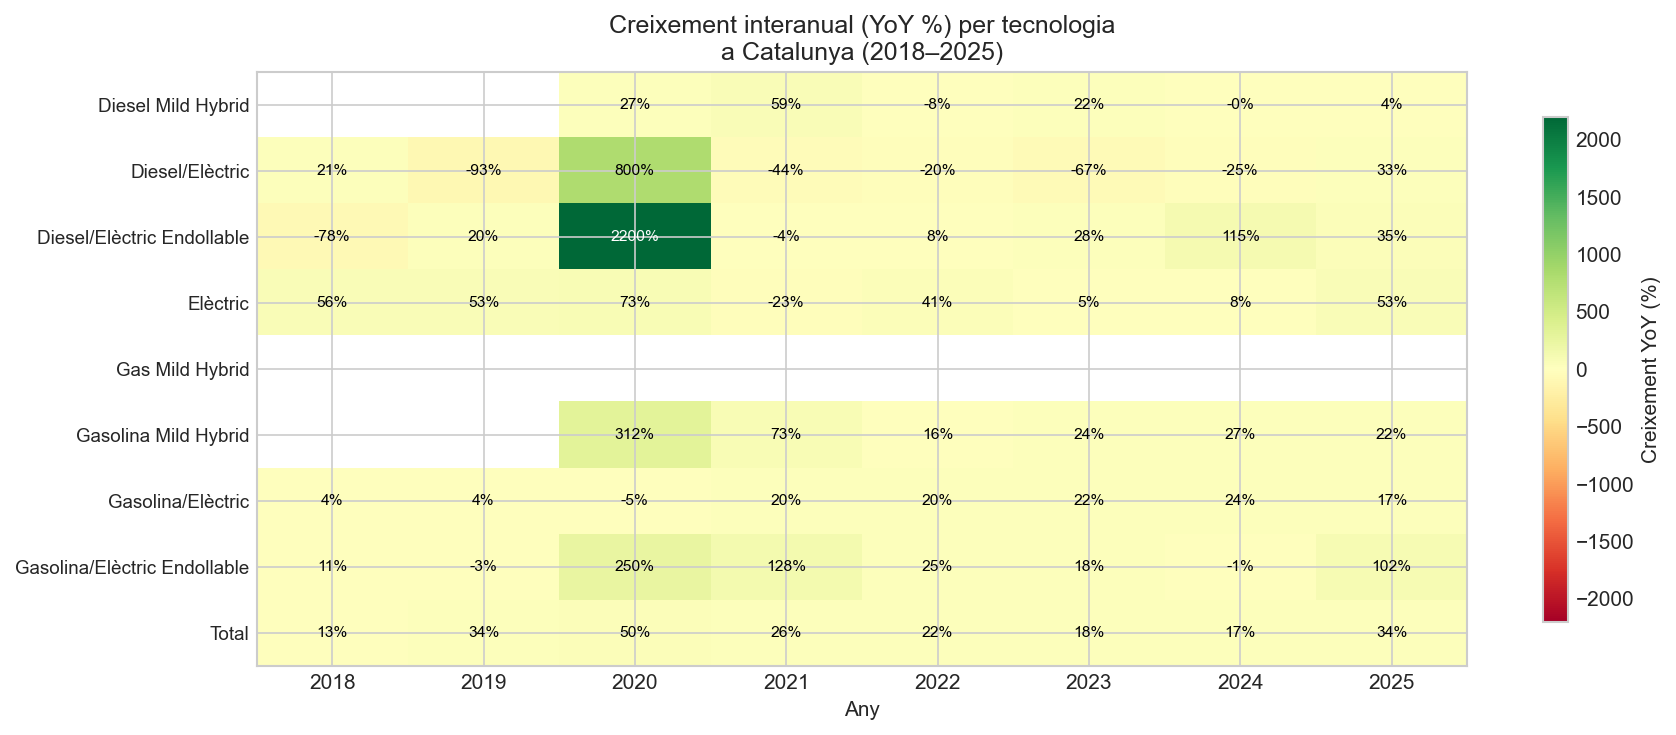

In [13]:
years = list(range(2018, 2026))
techs_all = [t for t in df['Tecnologia'].unique()]

heatmap_data = {}
for tech in techs_all:
    grp = df[df['Tecnologia'] == tech]
    yearly = grp.groupby('Any')['Matriculacions'].sum()
    yoy = {}
    for y in years:
        if y - 1 in yearly.index and yearly[y - 1] > 0:
            yoy[y] = (yearly.get(y, 0) - yearly[y - 1]) / yearly[y - 1] * 100
        else:
            yoy[y] = np.nan
    heatmap_data[tech] = yoy

heatmap_df = pd.DataFrame(heatmap_data).T[years]

fig, ax = plt.subplots(figsize=(12, 5))
vmax = max(abs(heatmap_df.values[~np.isnan(heatmap_df.values)]).max(), 1)
im = ax.imshow(heatmap_df.values, cmap='RdYlGn', aspect='auto',
               vmin=-vmax, vmax=vmax)

ax.set_xticks(range(len(years)))
ax.set_xticklabels(years)
ax.set_yticks(range(len(heatmap_df.index)))
ax.set_yticklabels(heatmap_df.index, fontsize=9)

for i in range(len(heatmap_df.index)):
    for j in range(len(years)):
        val = heatmap_df.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f'{val:.0f}%', ha='center', va='center',
                    fontsize=7.5, color='black' if abs(val) < vmax * 0.6 else 'white')

plt.colorbar(im, ax=ax, label='Creixement YoY (%)', shrink=0.85)
ax.set_title('Creixement interanual (YoY %) per tecnologia\na Catalunya (2018–2025)', fontsize=12)
ax.set_xlabel('Any')
fig.tight_layout()

save_fig(fig, 'fig_05_yoy_heatmap.png')
plt.show()

### 2.7 Distribució mensual (diagrames de caixa)

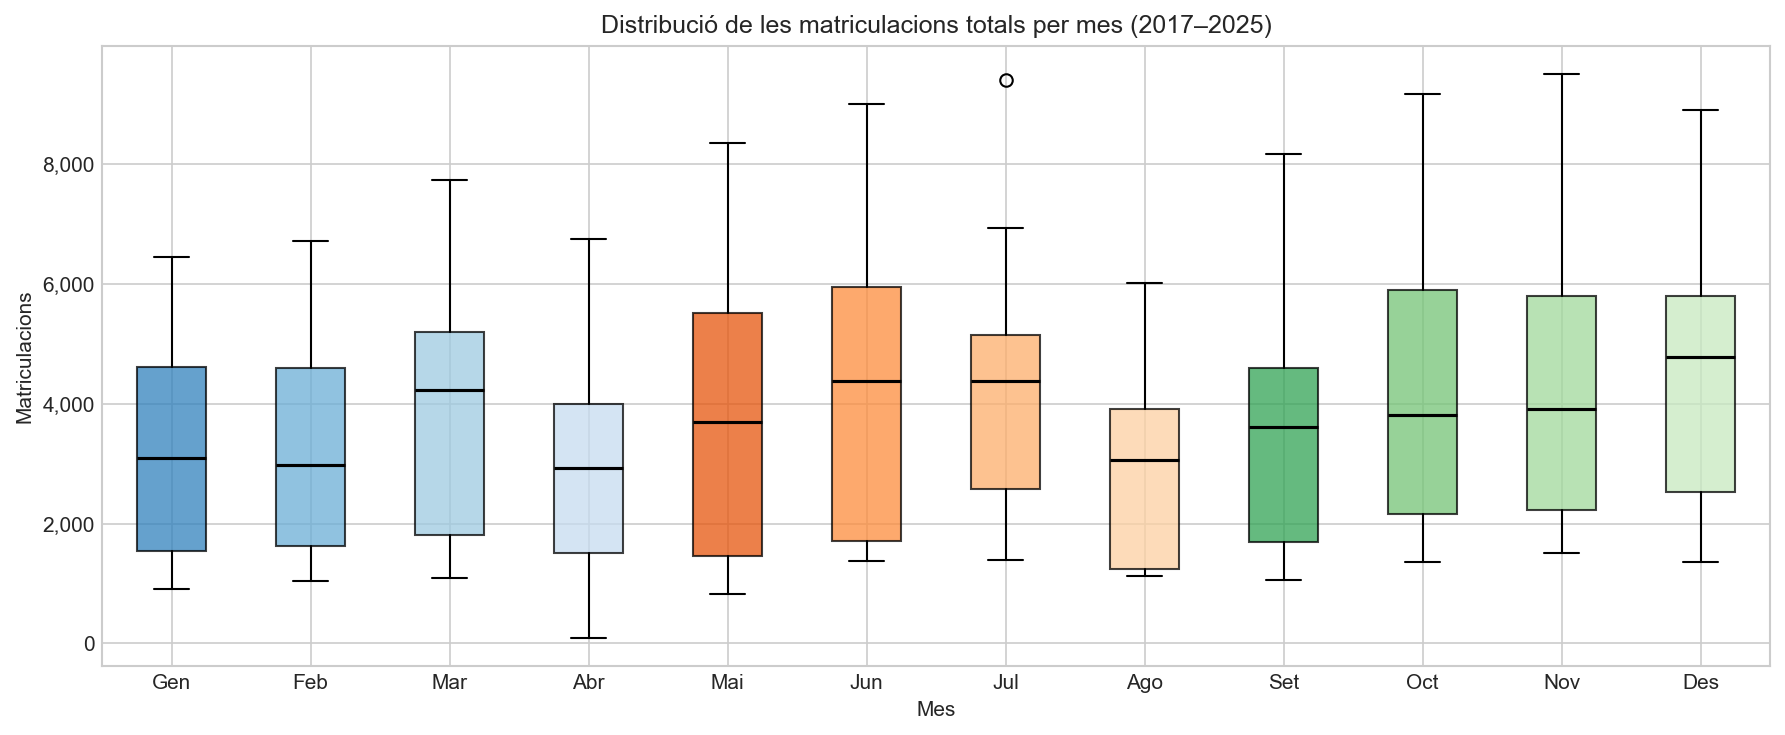

In [14]:
total_monthly = df[df['Tecnologia'] == 'Total'].copy()
month_labels = ['Gen', 'Feb', 'Mar', 'Abr', 'Mai', 'Jun',
                'Jul', 'Ago', 'Set', 'Oct', 'Nov', 'Des']

monthly_groups = [total_monthly[total_monthly['Mes'] == m]['Matriculacions'].values
                  for m in range(1, 13)]

fig, ax = plt.subplots(figsize=(12, 5))
bp = ax.boxplot(monthly_groups, patch_artist=True, notch=False,
                medianprops=dict(color='black', linewidth=1.5))

for patch, color in zip(bp['boxes'], plt.cm.tab20c.colors[:12]):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.set_title('Distribució de les matriculacions totals per mes (2017–2025)', fontsize=12)
ax.set_xlabel('Mes')
ax.set_ylabel('Matriculacions')
ax.yaxis.set_major_formatter(thousands_fmt)
fig.tight_layout()

save_fig(fig, 'fig_06_boxplots_monthly.png')
plt.show()

### 2.8 ACF i PACF (sèrie total)

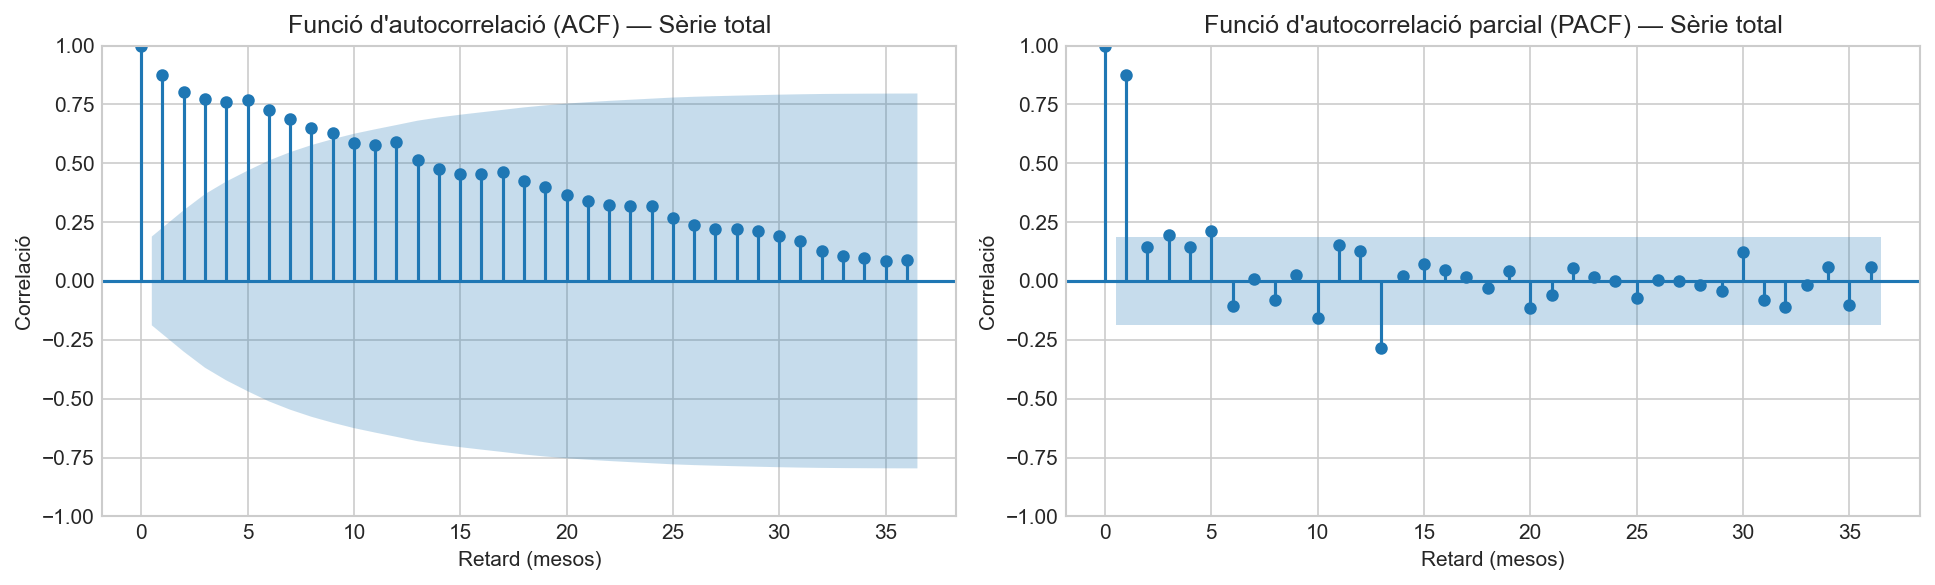

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

plot_acf(ts_total.dropna(), lags=36, ax=ax1, alpha=0.05,
         title='Funció d\'autocorrelació (ACF): Sèrie total')
plot_pacf(ts_total.dropna(), lags=36, ax=ax2, alpha=0.05, method='ywm',
          title='Funció d\'autocorrelació parcial (PACF): Sèrie total')

for ax in (ax1, ax2):
    ax.set_xlabel('Retard (mesos)')
    ax.set_ylabel('Correlació')

fig.tight_layout()
save_fig(fig, 'fig_07_acf_pacf.png')
plt.show()

#### Interpretació ACF / PACF

L'ACF mostra autocorrelació positiva significativa als retards 1, 2 i 3 (inèrcia mensual), i pics destacats als retards múltiples de 12 (lag 12, 24, 36), indicant estacionalitat anual persistent i forta. La PACF mostra un tall brusc després del primer retard, cosa que suggereix que la dependència temporal és majoritàriament de primer ordre un cop controlats els retards intermedis; el pic al lag 12 confirma la component estacional.

En conjunt, la sèrie presenta tendència creixent (l'ACF decai lentament sense tallar a zero) i estacionalitat anual clara. La no-estacionarietat és evident i cal almenys una diferenciació regular (d=1) i possiblement una diferenciació estacional (D=1). Un model SARIMA(p,d,q)(P,D,Q)₁₂ o equivalent amb diferenciació estacional sembla adequat.

### 2.9 Tests d'estacionarietat (ADF)

In [16]:
def run_adf(series, label):
    clean = series.dropna()
    result = adfuller(clean, autolag='AIC')
    stat, pval, lags_used, _, crit, _ = result
    conclusion = 'Estacionària ✓' if pval < 0.05 else 'No estacionària ✗'
    return {
        'Sèrie': label,
        'Estadístic ADF': round(stat, 4),
        'p-valor': round(pval, 4),
        'Retards usats': lags_used,
        'Valor crític 1%': round(crit['1%'], 4),
        'Valor crític 5%': round(crit['5%'], 4),
        'Valor crític 10%': round(crit['10%'], 4),
        'Conclusió': conclusion,
    }

log_series = np.log(ts_total.replace(0, np.nan))
diff_series = ts_total.diff()

adf_results = pd.DataFrame([
    run_adf(ts_total,    '(a) Sèrie original'),
    run_adf(diff_series, '(b) Primera diferència'),
    run_adf(log_series,  '(c) Log-transformada'),
]).set_index('Sèrie')

print('=== Test de Dickey-Fuller Augmentat (ADF) ===')
adf_results

=== Test de Dickey-Fuller Augmentat (ADF) ===


,Estadístic ADF,p-valor,Retards usats,Valor crític 1%,Valor crític 5%,Valor crític 10%,Conclusió
Sèrie,,,,,,,
(a) Sèrie original,2.2469,0.9989,12,-3.5011,-2.8925,-2.5833,No estacionària ✗
(b) Primera diferència,-2.9936,0.0355,11,-3.5011,-2.8925,-2.5833,Estacionària ✓
(c) Log-transformada,-0.2358,0.9341,11,-3.5004,-2.8922,-2.5831,No estacionària ✗


### 2.10 Resum de les troballes clau

---

**Tendència:**  
La sèrie total mostra una **tendència creixent sostinguda** des de 2017 fins a 2025, amb una acceleració notable a partir de 2020–2021 impulsada per les polítiques d'incentiu (MOVES III, etc.). L'impacte del **COVID-19** (mar–jun 2020) va provocar una caiguda abrupta seguida d'una ràpida recuperació. No s'observa ruptura estructural permanent: la tendència es repren a cotes superiors a les pre-pandèmia.

**Estacionalitat:**  
Existeix una **estacionalitat anual clara** (confirmada per la descomposició i l'ACF). Els **mesos de màxim** tipics són **octubre, novembre i desembre** (fi d'any fiscal/matricular), mentre que els **mesos de mínim** corresponen a **agost** (mes de vacances) i, secundàriament, **febrer**.

**Tecnologia dominant:**  
El **Gasolina Mild Hybrid** ha estat històricament dominant pel volum absolut. No obstant, s'observa una **transició estructural** progressiva cap a vehicles **100% Elèctric** i **Gasolina/Elèctric Endollable** (PHEV), que guanyen quota des de 2021. El Diesel Mild Hybrid i el Diesel/Elèctric mostren estancament o declivi.

**Estacionarietat:**  
La sèrie original **no és estacionària** (test ADF: p > 0.05). La **primera diferència** resulta estacionària, i la sèrie **log-transformada** redueix l'heteroscedasticitat però pot requerir també diferenciació. Per al modelatge, es recomana treballar amb la log-transformada diferenciada.

**Transformacions recomanades per al modelatge:**  
1. **Transformació logarítmica** (`log`) per estabilitzar la variància creixent.  
2. **Diferenciació regular d=1** per eliminar la tendència.  
3. **Diferenciació estacional D=1 (s=12)** per eliminar l'estacionalitat anual.  
4. Model candidat: **SARIMA(p,1,q)(P,1,Q)₁₂** sobre la sèrie log-transformada, o models de machine learning amb features calendàriques.

## Finalització: tancament del PDF i verificació

In [17]:
# Close the PDF
pdf_pages.close()
print(f'EDA_report.pdf desat correctament.')

# Final verification
dataset = pd.read_csv('dataset_treball.csv')
print('\n✓ Notebook executat correctament')
print(f'dataset_treball.csv shape: {dataset.shape}')

EDA_report.pdf desat correctament.

✓ Notebook executat correctament
dataset_treball.csv shape: (972, 5)
